## Linear delayed feedback — fit of the data

Fits of the onset tail speed of Danionella furing development.

Phase space with data. 

Figures are saved to the project `figures/` directory and to `delayed_feedback_model/media/`.

In [21]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import SPEED_ONSETS_DIR, FIGURES_DIR, notebook_media_dir
path = str(SPEED_ONSETS_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("delayed_feedback_model"))

%load_ext autoreload
%autoreload 2
from functions.visual_flow_behavior_plotting import *
from functions.visual_flow_behavior_analysis import *
from functions.brain_analysis import *
from functions.utilities import *
from functions.feedback_models import *
from functions.freely_swimming import *

import os
import h5py
from ipywidgets import interact, IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from functools import partial
from lmfit import Model, Parameters
import matplotlib as mpl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
# path, path_media set in first cell via paths.SPEED_ONSETS_DIR and media_dir()

In [23]:
# path_media created in first cell via media_dir(path)

### Load:

In [24]:
with open(os.path.join(path,"vfish_low_eta_fishbyfish_stats.pkl"), "rb") as f:
    fish_yng_vfish = pickle.load(f)
with open(os.path.join(path,"vtail_low_eta_fishbyfish_stats.pkl"), "rb") as f:
    fish_yng_vtail = pickle.load(f)

In [25]:
with open(os.path.join(path,"vfish_high_eta_fishbyfish_stats.pkl"), "rb") as f:
    fish_old_vfish = pickle.load(f)
with open(os.path.join(path,"vtail_high_eta_fishbyfish_stats.pkl"), "rb") as f:
    fish_old_vtail = pickle.load(f)

In [26]:
with open(os.path.join(path,"vfish_intermidiate_fishbyfish_stats.pkl"), "rb") as f:
    fish_int_vfish = pickle.load(f)
with open(os.path.join(path,"vtail_intermidiate_fishbyfish_stats.pkl"), "rb") as f:
    fish_int_vtail = pickle.load(f)

In [27]:
fish_intint_vfish = {k: fish_int_vfish[k]['int'] for k in fish_int_vfish}
fish_intint_vtail = {k: fish_int_vtail[k]['int'] for k in fish_int_vtail}

In [28]:
fish_intcont_vfish = {k: fish_int_vfish[k]['cont'] for k in fish_int_vfish}
fish_intcont_vtail = {k: fish_int_vtail[k]['cont'] for k in fish_int_vtail}

In [29]:
fish_ids_yng=list(fish_yng_vtail.keys())
fish_ids_yng

['13_06May24_1', '13_30Oct24_3', '13_30Oct24_4', '20_05Jun24_1']

In [30]:
fish_ids_old=list(fish_old_vtail.keys())
fish_ids_old

['26_02May24_2', '28_04May24_1', '34_11Dec24_1', '34_11Dec24_3']

In [31]:
fish_ids_int=list(fish_intint_vtail.keys())
fish_ids_int

['17_21May24_2',
 '18_22May24_1',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '25_10Jun24_1']

In [32]:
fish_stats={'yng':{'vfish':fish_yng_vfish,'vtail':fish_yng_vtail},
            'intcont':{'vfish':fish_intcont_vfish,'vtail':fish_intcont_vtail},
            'intint':{'vfish':fish_intint_vfish,'vtail':fish_intint_vtail},
            'old':{'vfish':fish_old_vfish,'vtail':fish_old_vtail}}

In [33]:
time=fish_stats['yng']['vfish'][fish_ids_yng[0]]['time_onset'] 

### Plot:

In [34]:
speed_factor=0.1

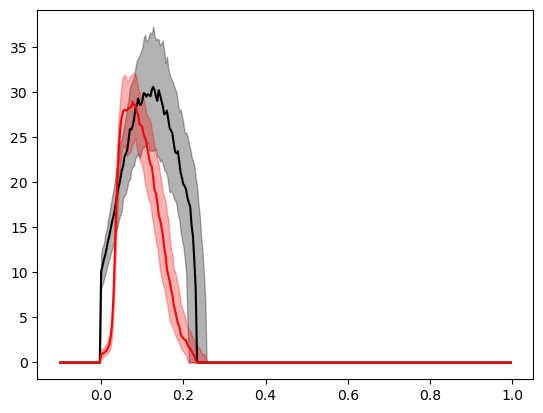

In [35]:
n_id=1
age_id='old'
fac=0.1

fig,ax=plt.subplots()

med=fish_stats[age_id]['vfish'][list(fish_stats[age_id]['vfish'].keys())[n_id]]['median']
iqm=fish_stats[age_id]['vfish'][list(fish_stats[age_id]['vfish'].keys())[n_id]]['iqr_minus']
iqp=fish_stats[age_id]['vfish'][list(fish_stats[age_id]['vfish'].keys())[n_id]]['iqr_plus']

ax.plot(time,med,'k',alpha=1)
ax.fill_between(time,med-iqm,med+iqp,color='k',alpha=0.3)

med=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[n_id]]['median']
iqm=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[n_id]]['iqr_minus']
iqp=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[n_id]]['iqr_plus']

ax.plot(time,fac*med,'r',alpha=1)
ax.fill_between(time,fac*(med-iqm),fac*(med+iqp),color='r',alpha=0.3)

plt.show()

### Fit:

#### Tail speed:

In [36]:
n_id=2
age_id='old'

In [37]:
speed_id='vtail'

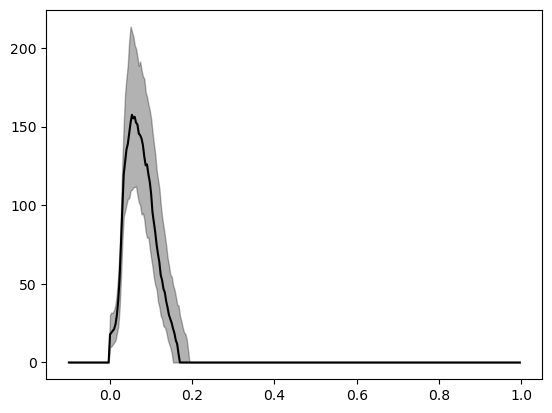

In [38]:
fig,ax=plt.subplots()

med=fish_stats[age_id][speed_id][list(fish_stats[age_id]['vfish'].keys())[n_id]]['median']
iqm=fish_stats[age_id][speed_id][list(fish_stats[age_id]['vfish'].keys())[n_id]]['iqr_minus']
iqp=fish_stats[age_id][speed_id][list(fish_stats[age_id]['vfish'].keys())[n_id]]['iqr_plus']

ax.plot(time,med,'k',alpha=1)
ax.fill_between(time,med-iqm,med+iqp,color='k',alpha=0.3)

plt.show()

In [39]:
params = Parameters()
params.add('k',value=1,min=0,vary=1)
params.add('tau',value=0.1,min=0,vary=1)
params.add('vi',value=6,min=0,vary=1)
params.add('vt',value=5,min=0,vary=1)
params.add('t0',value=0,vary=0)
params.add('N',value=30,vary=0)
params.add('set_to_zero',value=1,vary=0)

model = Model(delay_rescaled_solution)
result = model.fit(med, params, t=time)       

In [40]:
result.params

name,value,standard error,relative error,initial value,min,max,vary
k,16.3807320,1.8825e+10,(114919379139.86%),1.0,0.00000000,inf,1
tau,0.09333377,0.00555226,(5.95%),0.1,0.00000000,inf,1
vi,108.681758,2.78805869,(2.57%),6.0,0.00000000,inf,1
vt,16.7693411,1.0563e+11,(629870798682.59%),5.0,0.00000000,inf,1
t0,0.00000000,0.00000000,,0.0,-inf,inf,0
N,30.0000000,0.00000000,(0.00%),30.0,-inf,inf,0
set_to_zero,1.00000000,0.00000000,(0.00%),1.0,-inf,inf,0


<Axes: title={'center': 'Model(delay_rescaled_solution)'}, xlabel='t', ylabel='y'>

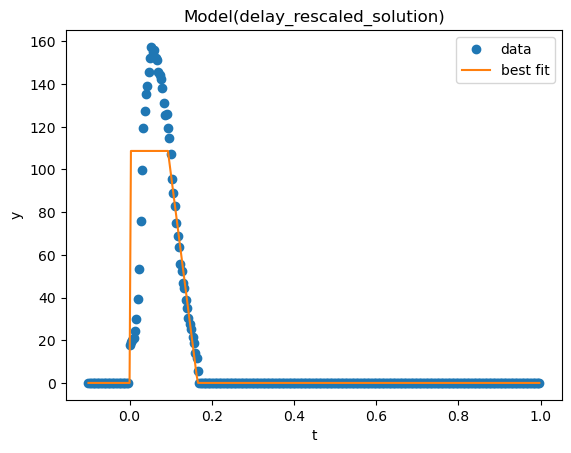

In [41]:
result.plot_fit()

#### Fish speed:

In [42]:
speed_id='vfish'

In [44]:
params = Parameters()
params.add('k',value=1,min=0,vary=1)
params.add('tau',value=0.1,min=0,vary=1)
params.add('vi',value=10,min=0,vary=0)
params.add('vt',value=1,min=0,vary=0)
params.add('t0',value=0.05,vary=0)
params.add('N',value=30,vary=0)
params.add('set_to_zero',value=1,vary=0)

model = Model(delay_rescaled_solution)
result = model.fit(med, params, t=time)       

In [45]:
result.params

name,value,standard error,relative error,initial value,min,max,vary
k,12.2652414,29.2762333,(238.69%),1.0,0.00000000,inf,1
tau,0.09333454,0.12718562,(136.27%),0.1,0.00000000,inf,1
vi,10.0000000,0.00000000,(0.00%),10.0,0.00000000,inf,0
vt,1.00000000,0.00000000,(0.00%),1.0,0.00000000,inf,0
t0,0.05000000,0.00000000,(0.00%),0.05,-inf,inf,0
N,30.0000000,0.00000000,(0.00%),30.0,-inf,inf,0
set_to_zero,1.00000000,0.00000000,(0.00%),1.0,-inf,inf,0


<Axes: title={'center': 'Model(delay_rescaled_solution)'}, xlabel='t', ylabel='y'>

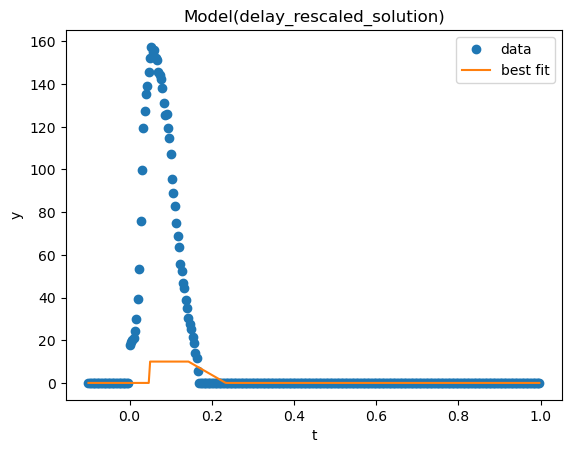

In [46]:
result.plot_fit()

### Fit all fish:

In [47]:
k0=10
tau0=0.1
vt0=30
taumin=0.05
taumax=0.5
vtmin=20
vtmax=60

maxtime=0.75
valueafter=-50

#### Young:

k = 4.3007834844282895
tau = 0.18818998305333406
vi = 59.64842802802886
vt = 51.86982379595034
t0 = 0.0
N = 30.0
set_to_zero = 1.0


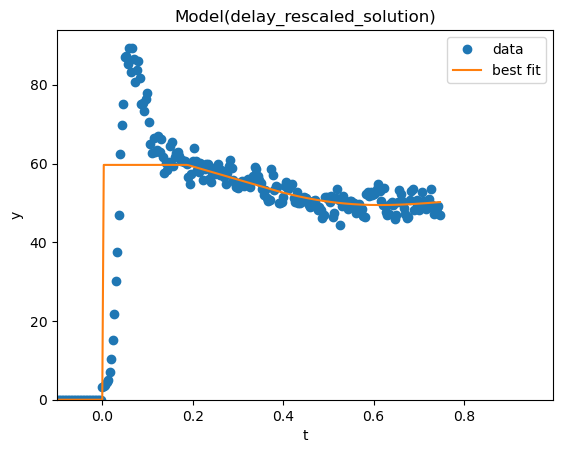

k = 5.045962386178206
tau = 0.1027243104997768
vi = 37.11519592302043
vt = 20.556867300695572
t0 = 0.0
N = 30.0
set_to_zero = 1.0


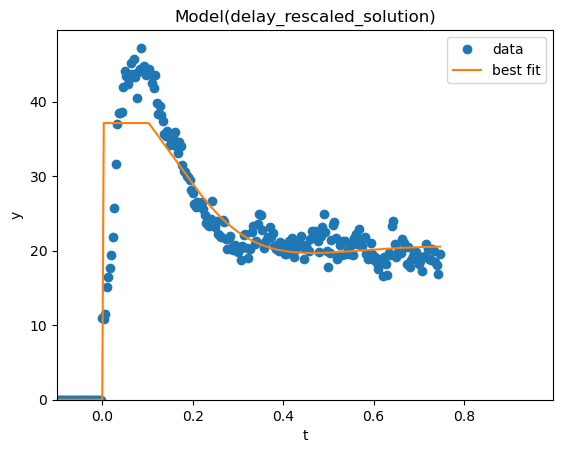

k = 4.836852859461054
tau = 0.08624669652074762
vi = 42.63727516227961
vt = 24.918770411014727
t0 = 0.0
N = 30.0
set_to_zero = 1.0


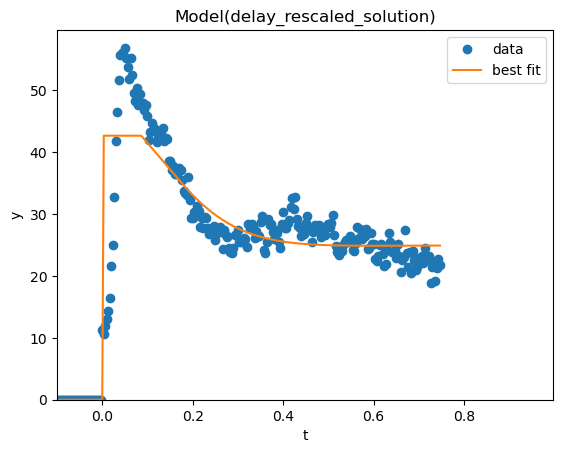

k = 2.9707919369273004
tau = 0.09311885735457873
vi = 50.931947968618154
vt = 25.410163412866275
t0 = 0.0
N = 30.0
set_to_zero = 1.0


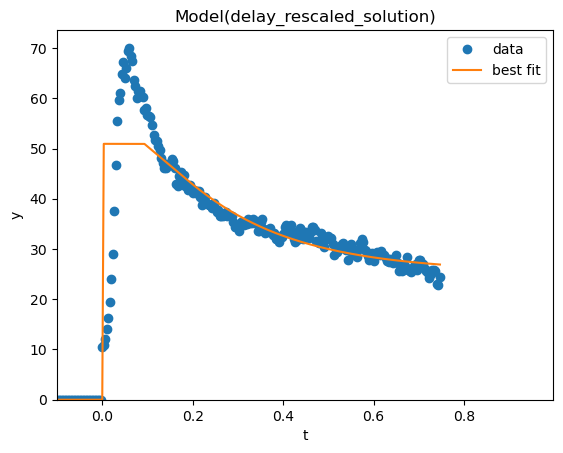

In [48]:
param_values_yng=fit_speed_onsets_for_all_fish('yng','vtail',time,fish_stats,k0=k0,tau0=tau0,vt0=vt0,taumin=taumin,taumax=taumax,vtmin=vtmin,vtmax=vtmax,maxtime=maxtime,valueafter=valueafter,crop=1)

#### Intermediate, continuous:

k = 9.695746170994811
tau = 0.08450108269411374
vi = 46.72004873903244
vt = 31.737904269401277
t0 = 0.0
N = 30.0
set_to_zero = 1.0


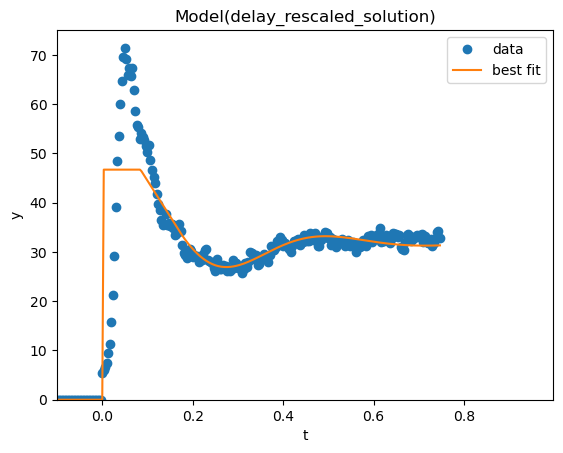

k = 6.676703147232437
tau = 0.11763353260663725
vi = 55.1018606338774
vt = 37.21401649834806
t0 = 0.0
N = 30.0
set_to_zero = 1.0


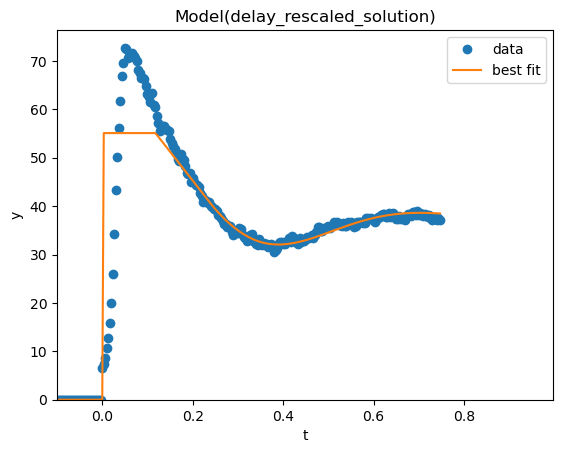

k = 6.916462713586507
tau = 0.08999823512480852
vi = 62.32096525785167
vt = 33.61676224086955
t0 = 0.0
N = 30.0
set_to_zero = 1.0


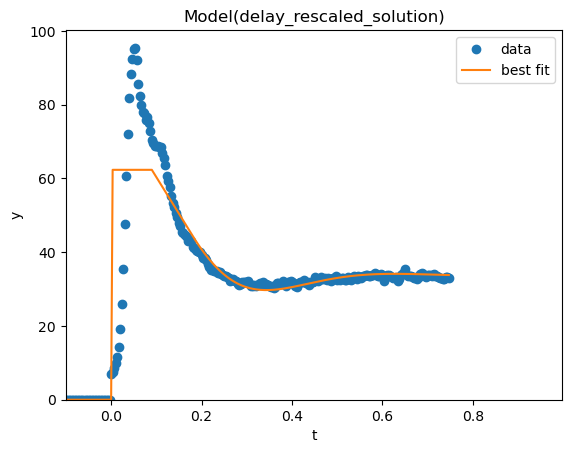

k = 7.816751608012815
tau = 0.09072122086702838
vi = 50.04239125724156
vt = 41.30594856820906
t0 = 0.0
N = 30.0
set_to_zero = 1.0


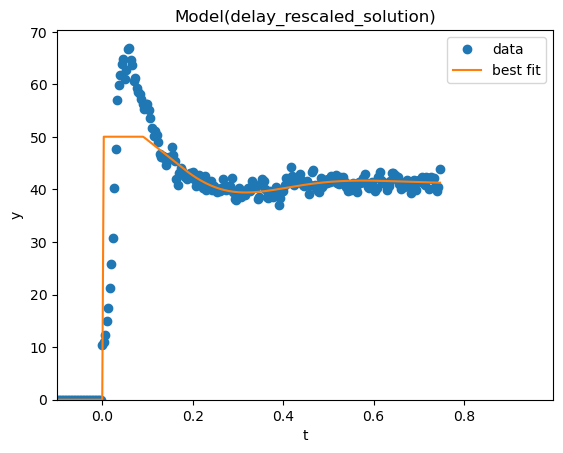

k = 6.605288318563601
tau = 0.09536839753863832
vi = 81.06048076157835
vt = 54.80086433834448
t0 = 0.0
N = 30.0
set_to_zero = 1.0


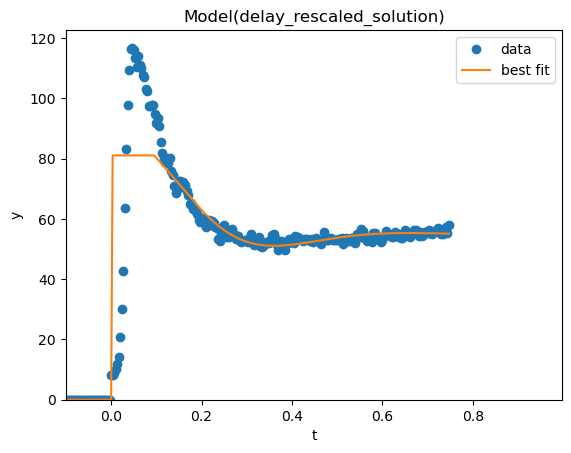

k = 10.1343961157035
tau = 0.09666684342965434
vi = 56.33331447255285
vt = 48.60525585522983
t0 = 0.0
N = 30.0
set_to_zero = 1.0


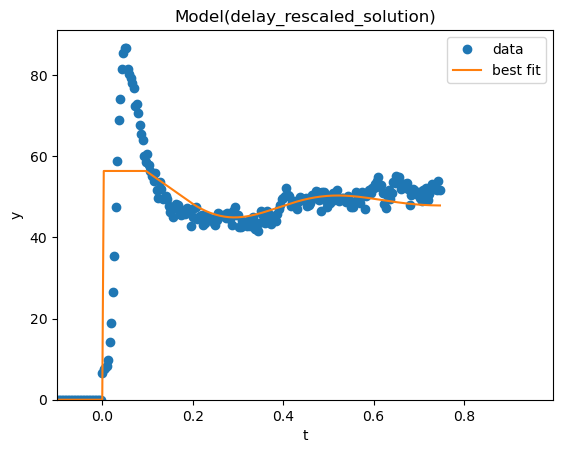

k = 9.037785465104525
tau = 0.10651991065877389
vi = 34.82518505631642
vt = 30.2084123304071
t0 = 0.0
N = 30.0
set_to_zero = 1.0


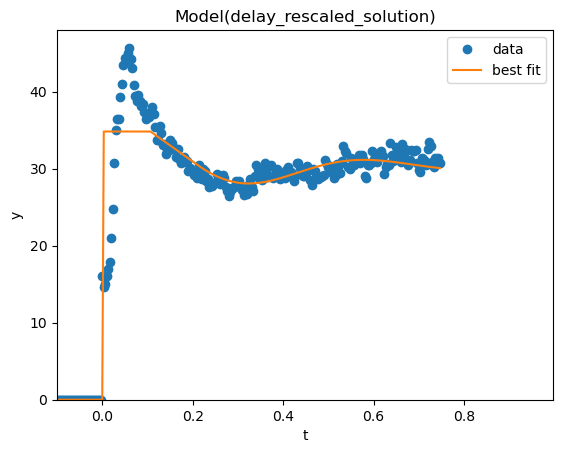

k = 7.842358323595658
tau = 0.17313911080892103
vi = 51.61218846048532
vt = 47.26013511016673
t0 = 0.0
N = 30.0
set_to_zero = 1.0


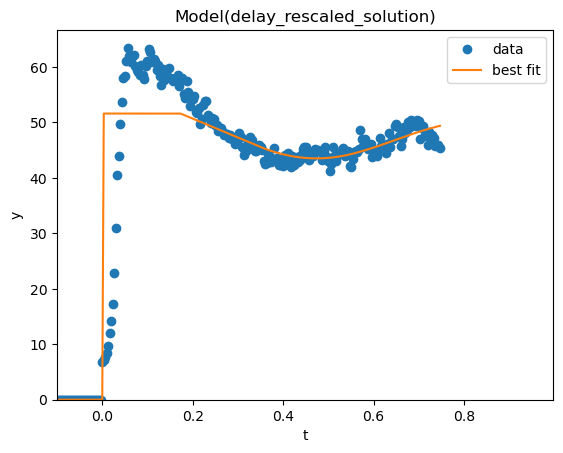

In [49]:
param_values_intcont=fit_speed_onsets_for_all_fish('intcont','vtail',time,fish_stats,k0=k0,tau0=tau0,vt0=vt0,taumin=taumin,taumax=taumax,vtmin=vtmin,vtmax=vtmax,maxtime=maxtime,valueafter=valueafter,crop=1)

#### Intermediate, intermittent:

k = 10.393369778878625
tau = 0.11084140587044691
vi = 58.543205714654526
vt = 20.00081010095657
t0 = 0.0
N = 30.0
set_to_zero = 1.0


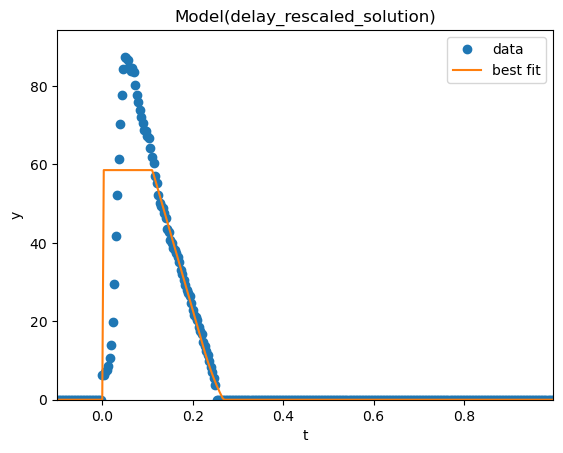

k = 7.642917775882076
tau = 0.16768422262382535
vi = 68.21438217008739
vt = 20.003392593744884
t0 = 0.0
N = 30.0
set_to_zero = 1.0


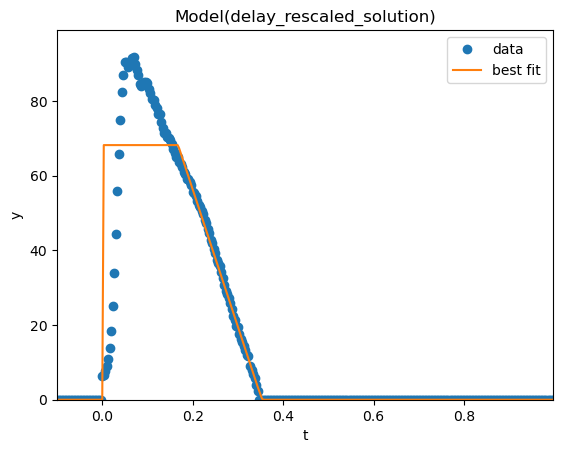

k = 7.480696479825314
tau = 0.13868205717574408
vi = 57.336427503443744
vt = 20.041584117069632
t0 = 0.0
N = 30.0
set_to_zero = 1.0


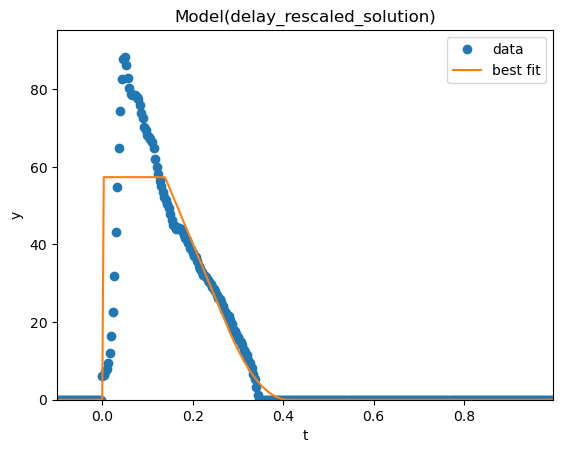

k = 6.956502308066263
tau = 0.16207172384303903
vi = 51.94481567073888
vt = 20.02614491150885
t0 = 0.0
N = 30.0
set_to_zero = 1.0


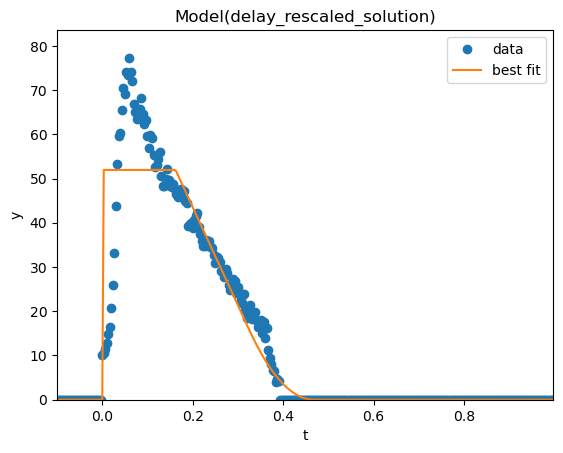

k = 9.830462438653116
tau = 0.10120202039661386
vi = 93.67721721724618
vt = 31.00981795263513
t0 = 0.0
N = 30.0
set_to_zero = 1.0


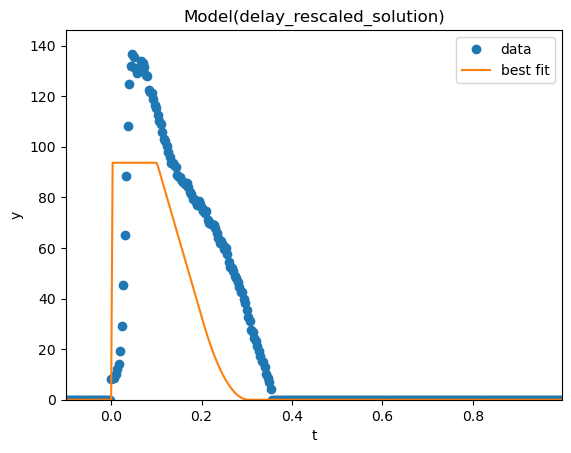

k = 9.959848529671111
tau = 0.11208069267515888
vi = 59.685965082531155
vt = 20.000011838092423
t0 = 0.0
N = 30.0
set_to_zero = 1.0


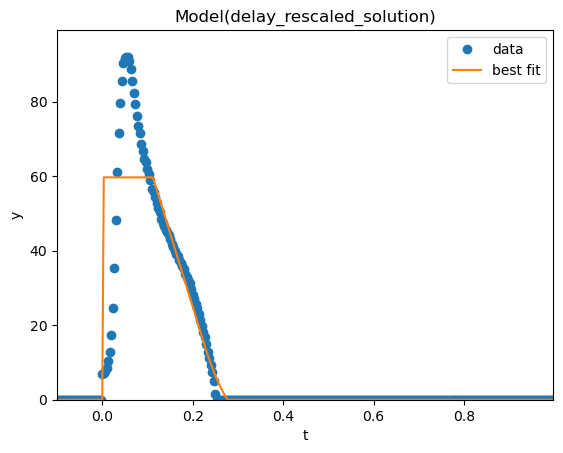

k = 13.077296046930185
tau = 0.15559358478502933
vi = 44.005602568253444
vt = 20.350634687400348
t0 = 0.0
N = 30.0
set_to_zero = 1.0


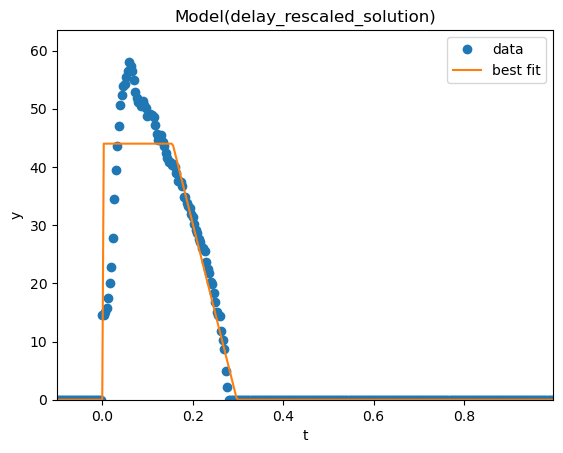

k = 10.686327604150083
tau = 0.19300495391086375
vi = 47.809159478294724
vt = 21.7960534102366
t0 = 0.0
N = 30.0
set_to_zero = 1.0


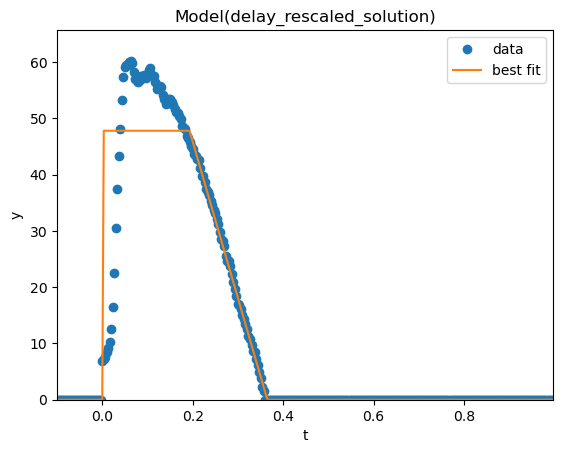

In [50]:
param_values_intint=fit_speed_onsets_for_all_fish('intint','vtail',time,fish_stats,k0=k0,tau0=tau0,vt0=vt0,taumin=taumin,taumax=taumax,vtmin=vtmin,vtmax=vtmax,maxtime=maxtime,valueafter=valueafter,add_after=1)

#### Old:

k = 19.853737343622498
tau = 0.1258752524138878
vi = 145.58205546303083
vt = 59.99423589556912
t0 = 0.0
N = 30.0
set_to_zero = 1.0


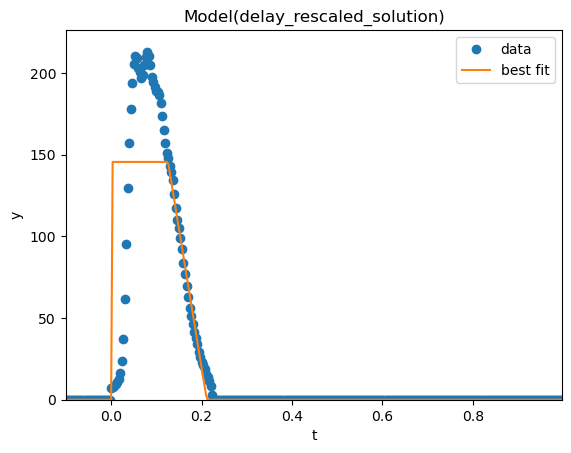

k = 18.02402638762759
tau = 0.12621944933477244
vi = 197.54129055950384
vt = 59.96047547566619
t0 = 0.0
N = 30.0
set_to_zero = 1.0


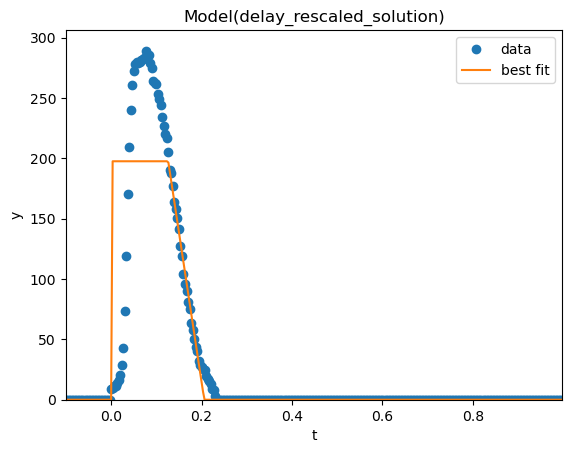

k = 20.55826571884093
tau = 0.09333367296366783
vi = 108.66928535367549
vt = 35.32019008452003
t0 = 0.0
N = 30.0
set_to_zero = 1.0


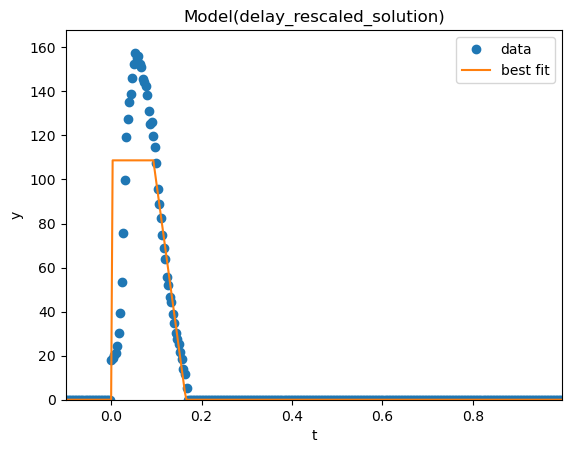

k = 12.676480977824763
tau = 0.12333328621591003
vi = 177.23640683882502
vt = 40.79317699011867
t0 = 0.0
N = 30.0
set_to_zero = 1.0


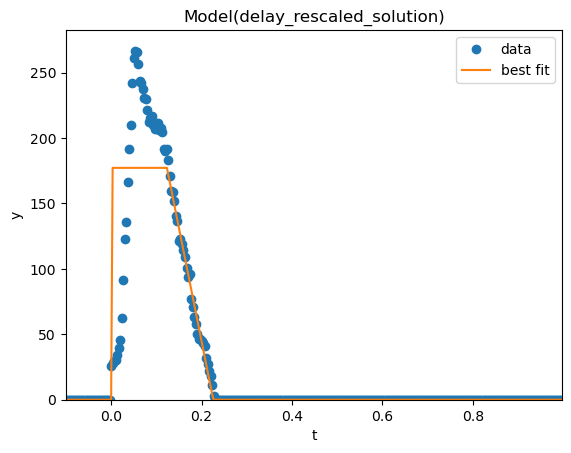

In [51]:
param_values_old=fit_speed_onsets_for_all_fish('old','vtail',time,fish_stats,k0=k0,tau0=tau0,vt0=vt0,taumin=taumin,taumax=taumax,vtmin=vtmin,vtmax=vtmax,maxtime=maxtime,valueafter=valueafter,add_after=1)

### Example fits:

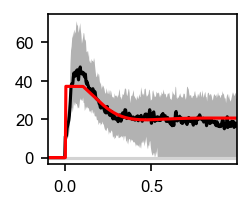

In [52]:
id=1
age_id='yng'

arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.25*textwidthSI,dpi=150)


med=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[id]]['median']
iqm=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[id]]['iqr_minus']
iqp=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[id]]['iqr_plus']

ax.axhline(0,c='lightgray')

ax.plot(time,med,'k',alpha=1)
ax.fill_between(time,med-iqm,med+iqp,color='k',alpha=0.3,ec='none')

ax.plot(time,delay_rescaled_solution(time,param_values_yng['k'][id],param_values_yng['tau'][id],param_values_yng['vi'][id],param_values_yng['vt'][id]),'r',alpha=1)

ax.set_xlim(time[0],time[-1])

plt.show()

In [53]:
param_values={'yng':param_values_yng,
              'intcont':param_values_intcont,
              'intint':param_values_intint,
              'old':param_values_old}

In [54]:
clist=['magenta','mediumblue','lightseagreen','purple']

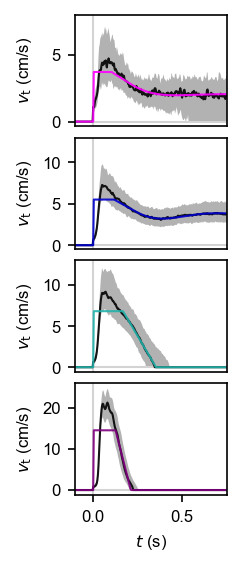

In [56]:
arial()
inline()
fig,axs=plt.subplots(4,1,figsize=np.array([1,3.2])*0.2*textwidthSI,dpi=150,sharex=True)
axs=axs.ravel()
plt.subplots_adjust(hspace=0.1,wspace=0.1)

id_list=[['yng',1],['intcont',1],['intint',1],['old',0]]
ymaxlist=speed_factor*np.array([80,130,130,260])

lw=1
alpha=0.9

for i,param in enumerate(id_list):
    ax=axs[i]
    age_id,id=param

    med=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[id]]['median']
    iqm=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[id]]['iqr_minus']
    iqp=fish_stats[age_id]['vtail'][list(fish_stats[age_id]['vfish'].keys())[id]]['iqr_plus']

    ax.axhline(0,color='lightgray',lw=lw)
    ax.axvline(0,color='lightgray',lw=lw)
    
    ax.plot(time,speed_factor*med,'k',alpha=alpha,lw=lw)
    ax.fill_between(time,speed_factor*(med-iqm),speed_factor*(med+iqp),color='k',alpha=0.3,ec='none')
    
    ax.plot(time,speed_factor*delay_rescaled_solution(time,param_values[age_id]['k'][id],param_values[age_id]['tau'][id],param_values[age_id]['vi'][id],param_values[age_id]['vt'][id]),
            c=clist[i],alpha=alpha,lw=lw)
    
    ax.set_xlim(time[0],maxtime)


    if i==3:
        ax.set_xlabel(r'$t$ (s)')
    else:
        ax.tick_params(bottom=False)
        
    ax.set_ylabel(r'$v_\mathrm{t}$ (cm/s)')

    ax.set_ylim(top=ymaxlist[i])

fig.align_labels()

plt.savefig(os.path.join(path_media,f'Fig_4d_examples_fits_onsets.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_4d_examples_fits_onsets.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

### Compare parameters:

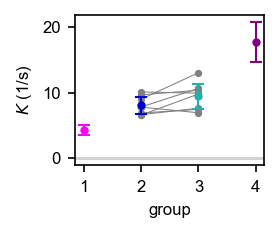

In [57]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.25*textwidthSI,dpi=150)
vmax=1
lw=1
capsize=3
param_id='k'

ax.axhline(0,c='lightgray')

for i in range(len(fish_ids_int)):
    ax.plot([2,3],[param_values_intcont[param_id][i],param_values_intint[param_id][i]],'.-',ms=5,c='gray',lw=0.5)

ax.errorbar(1,np.mean(param_values_yng[param_id]),np.std(param_values_yng[param_id]),fmt='.',c=clist[0],lw=lw,capsize=capsize)
ax.errorbar(2,np.mean(param_values_intcont[param_id]),np.std(param_values_intcont[param_id]),fmt='.',c=clist[1],lw=lw,capsize=capsize)
ax.errorbar(3,np.mean(param_values_intint[param_id]),np.std(param_values_intint[param_id]),fmt='.',c=clist[2],lw=lw,capsize=capsize)
ax.errorbar(4,np.mean(param_values_old[param_id]),np.std(param_values_old[param_id]),fmt='.',c=clist[3],lw=lw,capsize=capsize)

ax.set_xticks([1,2,3,4])

ax.set_xlabel('group')
ax.set_ylabel(r'$K$ (1/s)')

plt.show()

In [45]:
np.mean(param_values_old[param_id])/np.mean(param_values_yng[param_id])

np.float64(4.125901960638253)

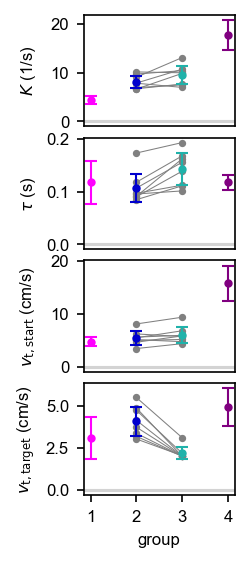

In [58]:
arial()
inline()
fig,axs=plt.subplots(4,1,figsize=np.array([1,3.2])*0.2*textwidthSI,dpi=150,sharex=True)
axs=axs.ravel()
plt.subplots_adjust(hspace=0.1,wspace=0.1)

lw=1
capsize=3

param_id_list=['k','tau','vi','vt']

for i,param_id in enumerate(param_id_list):
    ax=axs[i]

    if i==2 or i==3:
        factor=speed_factor
    else:
        factor=1
        
    ax.axhline(0,c='lightgray')
    
    for i in range(len(fish_ids_int)):
        ax.plot([2,3],[factor*param_values_intcont[param_id][i],factor*param_values_intint[param_id][i]],'.-',ms=5,c='gray',lw=0.5)
    
    ax.errorbar(1,factor*np.mean(param_values_yng[param_id]),factor*np.std(param_values_yng[param_id]),fmt='.',c=clist[0],lw=lw,capsize=capsize)
    ax.errorbar(2,factor*np.mean(param_values_intcont[param_id]),factor*np.std(param_values_intcont[param_id]),fmt='.',c=clist[1],lw=lw,capsize=capsize)
    ax.errorbar(3,factor*np.mean(param_values_intint[param_id]),factor*np.std(param_values_intint[param_id]),fmt='.',c=clist[2],lw=lw,capsize=capsize)
    ax.errorbar(4,factor*np.mean(param_values_old[param_id]),factor*np.std(param_values_old[param_id]),fmt='.',c=clist[3],lw=lw,capsize=capsize)

axs[0].set_ylabel(r'$K$ (1/s)')
axs[1].set_ylabel(r'$\tau$ (s)')
axs[2].set_ylabel(r'$v_\mathrm{t,start}$ (cm/s)')
axs[3].set_ylabel(r'$v_\mathrm{t,target}$ (cm/s)')
axs[3].set_xlabel('group')
axs[3].set_xticks([1,2,3,4])

for i in range(3):
    axs[i].tick_params(bottom=False)

fig.align_labels()

plt.savefig(os.path.join(path_media,f'Fig_4e_best_fit_params_onsets.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_4e_best_fit_params_onsets.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

In [59]:
param_values_yng['ktau']=np.array(param_values_yng['k'])*np.array(param_values_yng['tau'])
param_values_intcont['ktau']=np.array(param_values_intcont['k'])*np.array(param_values_intcont['tau'])
param_values_intint['ktau']=np.array(param_values_intint['k'])*np.array(param_values_intint['tau'])
param_values_old['ktau']=np.array(param_values_old['k'])*np.array(param_values_old['tau'])

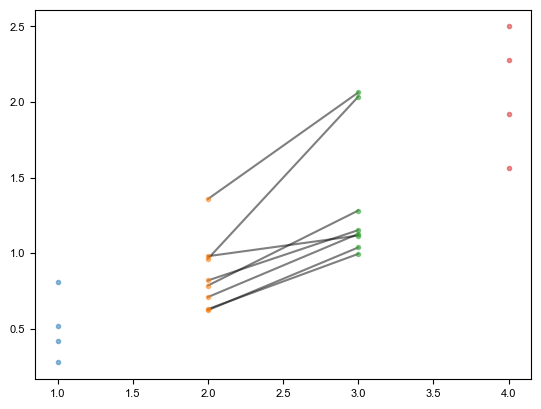

In [60]:
param_id='ktau'

fig,ax=plt.subplots()

ax.plot(1+np.zeros(len(param_values_yng[param_id])),param_values_yng[param_id],'.',alpha=0.5)
for i in range(len(fish_ids_int)):
    ax.plot([2,3],[param_values_intcont[param_id][i],param_values_intint[param_id][i]],'k-',alpha=0.5)
ax.plot(2+np.zeros(len(param_values_intcont[param_id])),param_values_intcont[param_id],'.',alpha=0.5)
ax.plot(3+np.zeros(len(param_values_intint[param_id])),param_values_intint[param_id],'.',alpha=0.5)
ax.plot(4+np.zeros(len(param_values_old[param_id])),param_values_old[param_id],'.',alpha=0.5)

plt.show()

In [61]:
param_values_yng['vratio']=np.array(param_values_yng['vi'])/np.array(param_values_yng['vt'])
param_values_intcont['vratio']=np.array(param_values_intcont['vi'])/np.array(param_values_intcont['vt'])
param_values_intint['vratio']=np.array(param_values_intint['vi'])/np.array(param_values_intint['vt'])
param_values_old['vratio']=np.array(param_values_old['vi'])/np.array(param_values_old['vt'])

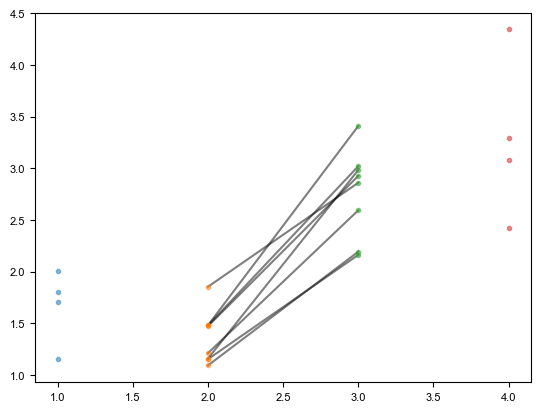

In [62]:
param_id='vratio'

fig,ax=plt.subplots()

ax.plot(1+np.zeros(len(param_values_yng[param_id])),param_values_yng[param_id],'.',alpha=0.5)
for i in range(len(fish_ids_int)):
    ax.plot([2,3],[param_values_intcont[param_id][i],param_values_intint[param_id][i]],'k-',alpha=0.5)
ax.plot(2+np.zeros(len(param_values_intcont[param_id])),param_values_intcont[param_id],'.',alpha=0.5)
ax.plot(3+np.zeros(len(param_values_intint[param_id])),param_values_intint[param_id],'.',alpha=0.5)
ax.plot(4+np.zeros(len(param_values_old[param_id])),param_values_old[param_id],'.',alpha=0.5)

plt.show()

### Phase space:

In [63]:
Npoints=300
tt=np.linspace(0,30,1000)
gs=np.linspace(0,2.5,Npoints)
xmins=np.zeros(len(gs))
tmins=np.zeros(len(gs))
xmaxs=np.zeros(len(gs))
tmaxs=np.zeros(len(gs))
for i in range(len(gs)):
    ys=delay_unit_solution(tt,k=gs[i],tau=1)
    xmins[i]=np.min(ys)
    tmins[i]=tt[np.argmin(ys)]
    xmaxs[i]=np.max(ys)
    tmaxs[i]=tt[np.argmax(ys)]
xmins[gs>np.pi/2]=np.nan
xmins[gs<1/np.e]=0
xmaxs[gs>np.pi/2]=np.nan

In [64]:
vt=1
vis=np.linspace(0,5,Npoints)
vmins=np.zeros((len(gs),len(vis)))
for i in range(len(gs)):
    for j in range(len(vis)):
        if vis[j]>1:
            vmins[i,j]=vt+(vis[j]-vt)*xmins[i]
        else:
            vmins[i,j]=vt+(vis[j]-vt)*xmaxs[i]

In [65]:
gs_b=get_linear_boundaries(gs)
vis_b=get_linear_boundaries(vis)

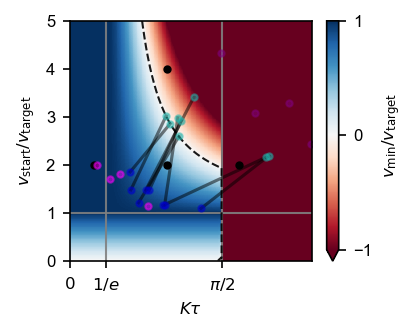

In [66]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.4*textwidthSI,dpi=150)
vmax=1
lw=1

cmap = mpl.colormaps['RdBu']
cmap.set_bad(color=cmap(0))

im=ax.pcolormesh(gs_b,vis_b,vmins.T,cmap=cmap,vmin=-vmax,vmax=vmax,rasterized=True)
cbar=fig.colorbar(im,ax=ax,extend='min')
cbar.set_label(r'$v_\mathrm{min}/v_\mathrm{target}$')
cbar.set_ticks([-1,0,1])
ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines,lw=lw)

maskmin=(gs>1/np.e+0.1)&(gs<np.pi/2)
maskmax=(xmaxs>1)&(gs<np.pi/2)
gs_boundary=np.concatenate([gs[maskmin],[np.pi/2,np.pi/2],gs[maskmax][::-1],[gs[maskmax][0]]])
vis_boundary=np.concatenate([vt-vt/xmins[maskmin],[vt-vt/xmins[maskmin][-1],vt-vt/xmaxs[maskmax][-1]],vt-vt/xmaxs[maskmax][::-1],[0]])
ax.plot(gs_boundary,vis_boundary,color='k',alpha=alphalines,ls='--',lw=lw)

params=[[2,0.25],[2,1],[4,1],[2,1.75]]
ax.plot([param[1] for param in params],[param[0] for param in params],'k.')

for i in range(len(param_values_intcont['ktau'])):
    ax.plot([param_values_intcont['ktau'][i],param_values_intint['ktau'][i]],
            [param_values_intcont['vratio'][i],param_values_intint['vratio'][i]],'k-',alpha=0.5)

ax.plot(param_values_yng['ktau'],param_values_yng['vratio'],'.',alpha=0.5,c=clist[0])
ax.plot(param_values_intcont['ktau'],param_values_intcont['vratio'],'.',alpha=0.5,c=clist[1])
ax.plot(param_values_intint['ktau'],param_values_intint['vratio'],'.',alpha=0.5,c=clist[2])
ax.plot(param_values_old['ktau'],param_values_old['vratio'],'.',alpha=0.5,c=clist[3])

ax.set_xlim(gs_b[0],gs_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$K \tau$')
ax.set_ylabel(r'$v_\mathrm{start}/v_\mathrm{target}$')

plt.show()

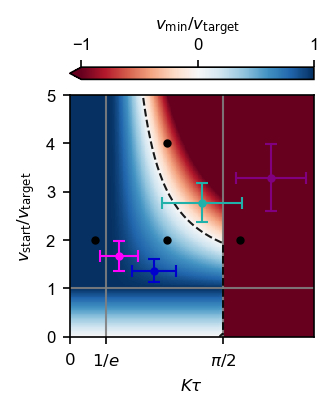

In [68]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,1.25])*0.3*textwidth,dpi=150)
vmax=1
lw=1
capsize=3

cmap = mpl.colormaps['RdBu']
cmap.set_bad(color=cmap(0))

im=ax.pcolormesh(gs_b,vis_b,vmins.T,cmap=cmap,vmin=-vmax,vmax=vmax,rasterized=True)
cbar=fig.colorbar(im,ax=ax,extend='min',location='top')
cbar.set_label(r'$v_\mathrm{min}/v_\mathrm{target}$')
cbar.set_ticks([-1,0,1])
ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines,lw=lw)

maskmin=(gs>1/np.e+0.1)&(gs<np.pi/2)
maskmax=(xmaxs>1)&(gs<np.pi/2)
gs_boundary=np.concatenate([gs[maskmin],[np.pi/2,np.pi/2],gs[maskmax][::-1],[gs[maskmax][0]]])
vis_boundary=np.concatenate([vt-vt/xmins[maskmin],[vt-vt/xmins[maskmin][-1],vt-vt/xmaxs[maskmax][-1]],vt-vt/xmaxs[maskmax][::-1],[0]])
ax.plot(gs_boundary,vis_boundary,color='k',alpha=alphalines,ls='--',lw=lw)

params=[[2,0.25],[2,1],[4,1],[2,1.75]]
ax.plot([param[1] for param in params],[param[0] for param in params],'k.')

ax.errorbar(param_values_yng['ktau'].mean(),param_values_yng['vratio'].mean(),
            xerr=param_values_yng['ktau'].std(),yerr=param_values_yng['vratio'].std(),fmt='.',lw=lw,capsize=capsize,c=clist[0])
ax.errorbar(param_values_intcont['ktau'].mean(),param_values_intcont['vratio'].mean(),
            xerr=param_values_intcont['ktau'].std(),yerr=param_values_intcont['vratio'].std(),fmt='.',lw=lw,capsize=capsize,c=clist[1])
ax.errorbar(param_values_intint['ktau'].mean(),param_values_intint['vratio'].mean(),
            xerr=param_values_intint['ktau'].std(),yerr=param_values_intint['vratio'].std(),fmt='.',lw=lw,capsize=capsize,c=clist[2])
ax.errorbar(param_values_old['ktau'].mean(),param_values_old['vratio'].mean(),
            xerr=param_values_old['ktau'].std(),yerr=param_values_old['vratio'].std(),fmt='.',lw=lw,capsize=capsize,c=clist[3])


ax.set_xlim(gs_b[0],gs_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$K \tau$')
ax.set_ylabel(r'$v_\mathrm{start}/v_\mathrm{target}$')

plt.savefig(os.path.join(path_media,f'Fig_4b_minimum_speed_heatmap_fit_params_examples.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_4b_minimum_speed_heatmap_fit_params_examples.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()